# 05 · Tensile-test analysis of ten S355 specimens: overview

**Goal.** Run the complete analysis of all ten tensile tests from the hosted research graphs, once from their PMDco 2 and once from their PMDco 3 description (generations 2 and 3 of the Platform MaterialDigital core ontology, PMDco), and show the results: properties per specimen, statistics per orientation, the comparison with the lab's values, and two overview figures.

**Audience.** All readers; the entry point for materials scientists and engineers (MSE domain experts).

**Prerequisites.** The terms of the tensile test (table below). No RDF or workflow knowledge is needed. The `pmd-demonstrator` environment from `environment.yml`, which installs the package `pmd_tensile`, and `ONTODOCKER_ADDRESS` (and `ONTODOCKER_TOKEN`, if the instance needs one) set in the environment before Jupyter starts. Neither is printed here.

**Reading paths.** MSE domain experts: **05** → [02](02-tensile-method.ipynb) → [01](01-tensile-data-from-graphs.ipynb) → [06](06-tensile-results-publication.ipynb). Ontologists and RDF experts: [01](01-tensile-data-from-graphs.ipynb) → [04](04-tensile-workflow-knowledge-graph.ipynb) → **05** → [06](06-tensile-results-publication.ipynb). Workflow developers: [03](03-tensile-workflow-building.ipynb) → [04](04-tensile-workflow-knowledge-graph.ipynb) → [02](02-tensile-method.ipynb) → **05** → [06](06-tensile-results-publication.ipynb). Readers new to Ontodocker and the Dataportal may start with [00](00-infrastructure-tour.ipynb).

| Symbol | Meaning | How it is computed (details in [notebook 02](02-tensile-method.ipynb)) | Unit |
| --- | --- | --- | --- |
| E | slope of the elastic line (not a material modulus) | least-squares slope of stress on strain, 10–40 % of ReH or Rp0.2 | GPa |
| ReH, ReL | upper and lower yield strength | stress at the peak before the first drop; lowest stress of the yield plateau | MPa |
| Rp0.2 | proof strength | stress at 0.2 % plastic strain | MPa |
| Fm, Rm | maximum force, tensile strength | largest force after yielding, Rm = Fm/S0 | N, MPa |
| Ag, Agt | plastic and total extension at Fm | strain at Fm, minus the elastic part for Ag | % |
| A, Z | elongation after fracture, reduction of area | from L0, Lu and S0, Su of the test record | % |
| e₀ | strain origin | strain where the elastic line crosses zero stress | % |
| u(S0)/S0 | scatter component of the relative uncertainty of S0 | scatter of the cross-section measurements | – |

All properties are defined by the method of [notebook 02](02-tensile-method.ipynb), inspired by ISO 6892-1; its limitations, and those of the data, are listed there in section 11.

*Execution class: network-read.* SPARQL queries to Ontodocker and the download of ten curve files from the public data host, once per ontology generation. Nothing is written to remote services or to disk.

## 1. Description and analysis

The research graphs say *what* was measured: which specimen was tested, its cross-section and gauge length, which CSV file holds its curve, which column is the force and in which unit. The analysis needs numbers and arrays in known units, not the concepts. The workflow therefore has a boundary:

```
graph (PMDco 2 or PMDco 3) --exploration--> specimen IDs
                           --acquisition--> neutral records --analysis--> properties, flags, uncertainty components
```

- **Exploration** and **acquisition** are the only steps that know an ontology. An *ontology profile*, selected by the workflow input `profile_id`, holds the ontology-specific SPARQL queries and unit conventions (notebook 01).
- **Analysis** steps receive plain numbers and arrays with units. They see no IRI and no SPARQL query ([notebook 02](02-tensile-method.ipynb)).

Switching the ontology therefore means changing two inputs, `profile_id` and `source`. Section 3 checks that the results do not change.

## 2. Setup and the two runs

Select the `pmd-demonstrator` kernel. The second cell below is tagged `parameters` for papermill. The sources are the three hosted datasets of each generation (orientation groups); both describe the same ten tests and link the same curve files (PMDco 3 through the curve tables that this demonstrator added, notebook 01).

In [1]:
import os

import pandas as pd
from IPython.display import display

from pmd_tensile import orchestration, plotting
from pmd_tensile.nodes import workflows
from pmd_tensile.sources import ONTODOCKER_ADDRESS_ENV

pd.set_option("display.max_colwidth", None)  # flags and lab notes are long
pd.set_option("display.precision", 4)

if not os.environ.get(ONTODOCKER_ADDRESS_ENV, "").strip():
    raise RuntimeError("Set ONTODOCKER_ADDRESS (and ONTODOCKER_TOKEN if required) before starting Jupyter.")

In [2]:
orientations = ("parallel", "perpendicular", "diagonal")
sources = {
    "pmdco2-tto": {"kind": "ontodocker", "datasets": [f"pmdco2_tto_example_{o}" for o in orientations]},
    "pmdco3-tto": {"kind": "ontodocker", "datasets": [f"pmdco3_tto_example_{o}" for o in orientations]},
}

`orchestration.run_tensile_analysis` runs the two workflow stages: the exploration checks the source against the profile and lists the specimens; the batch runs one per-specimen workflow for each (acquisition, analysis, comparison with the lab values) and gathers the tables. Notebook 03 shows how the batch is built. The method parameters are the method's defaults. The timestamp taken just before the runs appears in the figures.

In [3]:
retrieved = pd.Timestamp.now(tz="Europe/Berlin").floor("s")
tensile = {profile_id: orchestration.run_tensile_analysis(profile_id, source) for profile_id, source in sources.items()}
for profile_id, run in tensile.items():
    print(f"{profile_id}: batch run {run.batch_run.status}, {len(run.specimen_ids)} specimens ({', '.join(run.specimen_ids)})")
print("Data retrieved:", retrieved)

pmdco2-tto: batch run finished, 10 specimens (Zd2, Zd3, Zx1, Zx2, Zx3, Zx4, Zy1, Zy2, Zy3, Zy4)
pmdco3-tto: batch run finished, 10 specimens (Zd2, Zd3, Zx1, Zx2, Zx3, Zx4, Zy1, Zy2, Zy3, Zy4)
Data retrieved: 2026-11-10 20:41:35+01:00


## 3. Same results from both ontology generations

The two runs differ only in `profile_id` and `source`. If the profiles map both descriptions to the same neutral records, and the curve bytes are the same, every result must be identical, down to the last digit, the flags and the lab values used in the comparison. The check compares the text representation of every cell of the three result tables (exact and NaN-aware) and the SHA-256 of each downloaded curve.

In [4]:
pmdco2, pmdco3 = tensile["pmdco2-tto"], tensile["pmdco3-tto"]


def identical(left: pd.DataFrame, right: pd.DataFrame) -> bool:
    """Same columns, rows and cell values; repr makes the comparison exact and NaN-aware."""
    return (
        list(left.columns) == list(right.columns)
        and left.shape == right.shape
        and bool((left.reset_index(drop=True).map(repr) == right.reset_index(drop=True).map(repr)).all().all())
    )


display(pd.DataFrame([
    {"table": name, "rows": len(getattr(pmdco2, name)), "columns": getattr(pmdco2, name).shape[1],
     "identical": identical(getattr(pmdco2, name), getattr(pmdco3, name))}
    for name in ("results", "orientation_summary", "comparison")
]).set_index("table"))
same_curves = [sid for sid in pmdco2.specimen_ids if pmdco2.curves[sid].sha256 == pmdco3.curves[sid].sha256]
print("Same specimen IDs in the same order:", pmdco2.specimen_ids == pmdco3.specimen_ids)
print(f"Same curve bytes (SHA-256): {len(same_curves)} of {len(pmdco2.specimen_ids)} specimens")

,rows,columns,identical
table,,,
results,10,38,True
orientation_summary,30,7,True
comparison,70,13,True


Same specimen IDs in the same order: True
Same curve bytes (SHA-256): 10 of 10 specimens


The tables below and the figures are drawn from the PMDco 2 run; the PMDco 3 run gives the same numbers. This shows that the result does not depend on the ontology generation, not that it is right: the limits of the method ([notebook 02, section 11](02-tensile-method.ipynb)) apply to both.

## 4. Properties per specimen

Undefined values are NaN, and the flags name the rule that produced them ([notebook 02](02-tensile-method.ipynb) explains each); the flags and lab notes are shown in full. No specimen is excluded. Ag and Agt are NaN on all ten specimens (`ag:extensometer_invalid`, `agt:extensometer_invalid`: the valid extensometer strain ends before the force maximum). The other flags:

- `extensometer:extensometer_ended_early`: the largest valid strain is below half of A; absent on Zx1 and Zy1, whose A cannot be computed (`a:missing_input`).
- `extensometer:near_rate_switch`: the extensometer end lies near the strain at which the test rate changes.
- `rp02:in_yield_plateau` (Zy3, Zy4): the 0.2 % crossing lies in the yield range, so this Rp0.2 is a plateau stress.
- `rel:single_minimum` (Zy3): ReL is the lowest stress before the recovery, at a dip at the end of the plateau.
- `e:window_sensitive` (Zd3, Zy3): E changes by more than 5 % across the grid of fit windows.

*Execution class: read-only (local), as are all remaining cells.*

In [5]:
result = pmdco2
results = result.results.set_index("specimen_id")
property_columns = ["orientation", "yield_type", "e_gpa", "reh_mpa", "rel_mpa", "rp02_mpa", "fm_n", "rm_mpa",
                    "ag_percent", "agt_percent", "a_percent", "z_percent"]
display(results[property_columns])
display(results[["notes", "flags"]])

,orientation,yield_type,e_gpa,reh_mpa,rel_mpa,rp02_mpa,fm_n,rm_mpa,ag_percent,agt_percent,a_percent,z_percent
specimen_id,,,,,,,,,,,,
Zd2,diagonal to rolling direction,discontinuous,200.9203,399.3685,395.4093,389.6655,62124.42,514.6371,NaN,NaN,33.3667,59.5634
Zd3,diagonal to rolling direction,discontinuous,158.6705,396.2100,389.7225,395.4470,61734.63,511.4420,NaN,NaN,33.2833,63.6111
Zx1,in rolling direction,discontinuous,194.3460,379.9224,373.0554,375.4920,61993.74,513.8909,NaN,NaN,NaN,56.3489
Zx2,in rolling direction,discontinuous,198.8678,378.8463,374.2157,373.5275,60666.44,503.6900,NaN,NaN,35.0000,58.8315
Zx3,in rolling direction,discontinuous,200.0756,379.4088,370.7641,375.8609,60627.81,503.5700,NaN,NaN,35.1667,58.0534
Zx4,in rolling direction,discontinuous,195.7558,388.6658,382.8679,381.9096,62252.80,518.7128,NaN,NaN,34.8333,60.5196
Zy1,perpendicular to rolling direction,discontinuous,209.8907,399.5549,393.7093,396.1765,61332.51,508.2285,NaN,NaN,NaN,53.5636
Zy2,perpendicular to rolling direction,discontinuous,213.8779,398.7837,392.7918,389.9908,61165.14,506.7115,NaN,NaN,35.0000,55.7327
Zy3,perpendicular to rolling direction,discontinuous,205.2504,407.6470,390.1871,395.7749,60930.20,504.9618,NaN,NaN,33.5667,58.2598


,notes,flags
specimen_id,,
Zd2,"Proben aus Stahlblech entnommen, diagonal der Walzrichtung",extensometer:extensometer_ended_early; extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid
Zd3,"Proben aus Stahlblech entnommen, diagonal der Walzrichtung",extensometer:extensometer_ended_early; extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid; e:window_sensitive
Zx1,In Walzrichtung aus Stahlblech entnommen; Abweichend von den anderen Proben. Weggeschwindigkeit wurde erhöht.,ag:extensometer_invalid; agt:extensometer_invalid; a:missing_input
Zx2,"In Walzrichtung aus Stahlblech entnommen; Extensometer nach 3,9 % Dehnung der Proben entfernt. Keine Erhöhung der Geschwindigkeit.",extensometer:extensometer_ended_early; extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid
Zx3,"In Walzrichtung aus Stahlblech entnommen; Extensometer nach 3,9 % Dehnung der Proben entfernt. Keine Erhöhung der Geschwindigkeit.",extensometer:extensometer_ended_early; extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid
Zx4,"In Walzrichtung aus Stahlblech entnommen; Extensometer nach 3,9 % Dehnung der Proben entfernt. Keine Erhöhung der Geschwindigkeit.",extensometer:extensometer_ended_early; extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid
Zy1,"Proben aus Stahlblech entnommen, entgegen der Walzrichtung",extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid; a:missing_input
Zy2,"Proben aus Stahlblech entnommen, entgegen der Walzrichtung",extensometer:extensometer_ended_early; extensometer:near_rate_switch; ag:extensometer_invalid; agt:extensometer_invalid
Zy3,"Proben aus Stahlblech entnommen, entgegen der Walzrichtung",extensometer:extensometer_ended_early; extensometer:near_rate_switch; rel:single_minimum; rp02:in_yield_plateau; ag:extensometer_invalid; agt:extensometer_invalid; e:window_sensitive


### Uncertainty components

The components are reported separately and never combined ([notebook 02, section 8](02-tensile-method.ipynb), which also lists what is not covered). `s0_u_rel` is the scatter of the cross-section measurements, relative to S0; it applies equally to every stress and to E, and the lab value uses the same S0. `e_r2` is the R² of the elastic line and `e_linearity_rel_diff` the relative difference of E fitted on 5–25 % and on 25–50 % of the reference stress, both diagnostics. The window ranges are E and Rp0.2 over a declared grid of fit windows. Panels (g) and (h) of the second figure show both.

In [6]:
display(results[["s0_u_rel", "e_gpa", "e_r2", "e_window_min_gpa", "e_window_max_gpa", "e_linearity_rel_diff",
                 "rp02_mpa", "rp02_window_min_mpa", "rp02_window_max_mpa"]])
print(f"s0_u_rel from {1e4 * results['s0_u_rel'].min():.1f} to {1e4 * results['s0_u_rel'].max():.1f} · 10⁻⁴")

,s0_u_rel,e_gpa,e_r2,e_window_min_gpa,e_window_max_gpa,e_linearity_rel_diff,rp02_mpa,rp02_window_min_mpa,rp02_window_max_mpa
specimen_id,,,,,,,,,
Zd2,0.0004,200.9203,1.0000,200.3162,201.5823,-0.0054,389.6655,389.6203,389.7016
Zd3,0.0008,158.6705,0.9954,152.0335,180.1149,-0.1411,395.4470,394.4426,395.5995
Zx1,0.0002,194.3460,1.0000,191.4990,195.0354,0.0140,375.4920,375.4607,375.6512
Zx2,0.0003,198.8678,1.0000,197.1933,199.5042,-0.0135,373.5275,373.5216,373.5416
Zx3,0.0003,200.0756,1.0000,197.6420,201.0138,0.0018,375.8609,375.8112,375.9922
Zx4,0.0003,195.7558,1.0000,193.3736,196.6105,-0.0236,381.9096,381.8389,382.0686
Zy1,0.0004,209.8907,1.0000,207.7065,211.0210,0.0225,396.1765,396.1588,396.1845
Zy2,0.0005,213.8779,1.0000,205.5380,214.3987,0.0641,389.9908,389.9723,390.3495
Zy3,0.0007,205.2504,1.0000,177.2922,206.5783,0.2448,395.7749,395.4343,395.8230


s0_u_rel from 1.7 to 7.7 · 10⁻⁴


## 5. Statistics per orientation

Descriptive statistics per orientation: `n` counts the specimens with a defined value; `sd` uses ddof = 1. What these few specimens per group can and cannot show is stated in [notebook 02, section 11](02-tensile-method.ipynb). Zx1 was tested at a different speed (lab note).

In [7]:
display(
    result.orientation_summary.pivot(index="quantity", columns=workflows.GROUP_COLUMN, values=["n", "mean", "sd"])
    .reindex(list(workflows.SUMMARY_QUANTITIES))
)

n                       \
orientation diagonal to rolling direction in rolling direction   
quantity                                                         
e_gpa                                 2.0                  4.0   
reh_mpa                               2.0                  4.0   
rel_mpa                               2.0                  4.0   
rp02_mpa                              2.0                  4.0   
fm_n                                  2.0                  4.0   
rm_mpa                                2.0                  4.0   
ag_percent                            0.0                  0.0   
agt_percent                           0.0                  0.0   
a_percent                             2.0                  3.0   
z_percent                             2.0                  4.0   

                                                                        mean  \
orientation perpendicular to rolling direction diagonal to rolling direction   
quantity                                                                       
e_gpa                                      4.0                      179.7954   
reh_mpa                                    4.0                      397.7893   
rel_mpa                                    4.0                      392.5659   
rp02_mpa                                   4.0                      392.5562   
fm_n                                       4.0                    61929.5250   
rm_mpa                                     4.0                      513.0396   
ag_percent                                 0.0                           NaN   
agt_percent                                0.0                           NaN   
a_percent                                  3.0                       33.3250   
z_percent                                  4.0                       61.5872   

                                                                     \
orientation in rolling direction perpendicular to rolling direction   
quantity                                                              
e_gpa                   197.2613                           210.0082   
reh_mpa                 381.7108                           403.3094   
rel_mpa                 375.2258                           393.9250   
rp02_mpa                376.6975                           395.9201   
fm_n                  61385.1975                         61352.7975   
rm_mpa                  509.9659                           508.4831   
ag_percent                   NaN                                NaN   
agt_percent                  NaN                                NaN   
a_percent                35.0000                            33.8222   
z_percent                58.4383                            55.6661   

                                       sd                       \
orientation diagonal to rolling direction in rolling direction   
quantity                                                         
e_gpa                             29.8752               2.6625   
reh_mpa                            2.2334               4.6574   
rel_mpa                            4.0212               5.2927   
rp02_mpa                           4.0882               3.6225   
fm_n                             275.6232             858.9347   
rm_mpa                             2.2593               7.5765   
ag_percent                            NaN                  NaN   
agt_percent                           NaN                  NaN   
a_percent                          0.0589               0.1667   
z_percent                          2.8621               1.7321   

                                                
orientation perpendicular to rolling direction  
quantity                                        
e_gpa                                   3.5887  
reh_mpa                                 4.7936  
rel_mpa                                 3.7048  
rp02_mpa                                4.7991  
fm_n          

## 6. Comparison with the lab's values

The lab reported Fm, Rm, ReH, Rp0.2, E, A and Z from its own software, with unknown settings, so the comparison is a consistency check ([notebook 02, sections 9 and 11](02-tensile-method.ipynb)). ReL is not compared (no lab value); `not_comparable` means that either value is missing.

The deviations are given in steps of the lab's resolution, the step of its reported values (1 N, 1 MPa, 1 GPa, 0.5 % for A, 1 % for Z): a deviation below one step is within the lab's rounding. The tolerances of the rule (Fm ±0.1 %, Rm ±(0.1 % + 0.5 MPa), ReH and Rp0.2 ±2 %, E ±10 %, A and Z ±0.5 percentage points) decide `within` or `outside`. Fm differs by tens of steps because the reported Fm appears to be computed back from the rounded Rm, so its row repeats the Rm row ([notebook 02, section 9](02-tensile-method.ipynb)).

In [8]:
comparison = result.comparison
display(comparison.pivot(index="quantity", columns="specimen_id", values="deviation_in_resolution")
        .reindex(columns=list(result.specimen_ids))
        .rename_axis(columns="deviation in steps of the lab's resolution"))
display(pd.crosstab(comparison["quantity"], comparison["outcome"]))
display(comparison[comparison["outcome"] != "within"][["specimen_id", "quantity", "computed", "reported", "outcome"]])

deviation in steps of the lab's resolution,Zd2,Zd3,Zx1,Zx2,Zx3,Zx4,Zy1,Zy2,Zy3,Zy4
quantity,,,,,,,,,,
a_percent,-0.2667,0.5667,NaN,0.0000,0.3333,-0.3333,NaN,0.0000,0.1333,-0.2000
e_gpa,-0.0797,-36.3295,0.3460,-0.1322,1.0756,-0.2442,-0.1093,-0.1221,-0.7496,0.0136
fm_n,-43.5800,53.6300,-13.2600,-37.5600,-52.1900,-35.2000,27.5100,-34.8600,-4.8000,3.3400
reh_mpa,0.3685,0.2100,-0.0776,-0.1537,0.4088,0.6658,0.5549,-0.2163,-0.3530,0.2518
rm_mpa,-0.3629,0.4420,-0.1091,-0.3100,-0.4300,-0.2872,0.2285,-0.2885,-0.0382,0.0305
rp02_mpa,-0.3345,NaN,0.4920,-0.4725,-0.1391,-0.0904,0.1765,-0.0092,NaN,-0.2618
z_percent,-0.4366,-0.3889,0.3489,-0.1685,0.0534,-0.4804,-0.4364,-0.2673,0.2598,0.1081


outcome,not_comparable,outside,within
quantity,,,
a_percent,2,0,8
e_gpa,0,1,9
fm_n,0,0,10
reh_mpa,0,0,10
rm_mpa,0,0,10
rp02_mpa,2,0,8
z_percent,0,0,10


,specimen_id,quantity,computed,reported,outcome
10,Zd3,rp02_mpa,395.4470,NaN,not_comparable
11,Zd3,e_gpa,158.6705,195.0,outside
19,Zx1,a_percent,NaN,NaN,not_comparable
47,Zy1,a_percent,NaN,NaN,not_comparable
59,Zy3,rp02_mpa,395.7749,NaN,not_comparable


The raw values and differences, computed minus lab value in the unit of each quantity (percentage points for A and Z). Panel (e) of the second figure shows the differences divided by their tolerances.

In [9]:
raw = comparison.assign(**{"computed − lab": comparison["deviation"], "lab": comparison["reported"]})
raw["quantity"] = raw["quantity"] + " / " + raw["unit"]
values = ["computed", "lab", "computed − lab"]
table = raw.pivot(index="quantity", columns="specimen_id", values=values).stack(level=0)
quantities = list(dict.fromkeys(raw["quantity"]))
display(table.reindex(pd.MultiIndex.from_product([quantities, values])).reindex(columns=list(result.specimen_ids)))
tolerances = comparison.drop_duplicates("quantity").set_index("quantity")["tolerance"]
print("Tolerances:", "; ".join(f"{quantity}: {tolerance}" for quantity, tolerance in tolerances.items()))

specimen_id                           Zd2         Zd3         Zx1         Zx2  \
fm_n / N       computed        62124.4200  61734.6300  61993.7400  60666.4400   
               lab             62168.0000  61681.0000  62007.0000  60704.0000   
               computed − lab    -43.5800     53.6300    -13.2600    -37.5600   
rm_mpa / MPa   computed          514.6371    511.4420    513.8909    503.6900   
               lab               515.0000    511.0000    514.0000    504.0000   
               computed − lab     -0.3629      0.4420     -0.1091     -0.3100   
reh_mpa / MPa  computed          399.3685    396.2100    379.9224    378.8463   
               lab               399.0000    396.0000    380.0000    379.0000   
               computed − lab      0.3685      0.2100     -0.0776     -0.1537   
rp02_mpa / MPa computed          389.6655    395.4470    375.4920    373.5275   
               lab               390.0000         NaN    375.0000    374.0000   
               computed − lab     -0.3345         NaN      0.4920     -0.4725   
e_gpa / GPa    computed          200.9203    158.6705    194.3460    198.8678   
               lab               201.0000    195.0000    194.0000    199.0000   
               computed − lab     -0.0797    -36.3295      0.3460     -0.1322   
a_percent / %  computed           33.3667     33.2833         NaN     35.0000   
               lab                33.5000     33.0000         NaN     35.0000   
               computed − lab     -0.1333      0.2833         NaN      0.0000   
z_percent / %  computed           59.5634     63.6111     56.3489     58.8315   
               lab                60.0000     64.0000     56.0000     59.0000   
               computed − lab     -0.4366     -0.3889      0.3489     -0.1685   

specimen_id                           Zx3         Zx4         Zy1         Zy2  \
fm_n / N       computed        60627.8100  62252.8000  61332.5100  61165.1400   
               lab             60680.0000  62288.0000  61305.0000  61200.0000   
               computed − lab    -52.1900    -35.2000     27.5100    -34.8600   
rm_mpa / MPa   computed          503.5700    518.7128    508.2285    506.7115   
               lab               504.0000    519.0000    508.0000    507.0000   
               computed − lab     -0.4300     -0.2872      0.2285     -0.2885   
reh_mpa / MPa  computed          379.4088    388.6658    399.5549    398.7837   
               lab               379.0000    388.0000    399.0000    399.0000   
               computed − lab      0.4088      0.6658      0.5549     -0.2163   
rp02_mpa / MPa computed          375.8609    381.9096    396.1765    389.9908   
               lab               376.0000    382.0000    396.0000    390.0000   
               computed − lab     -0.1391     -0.0904      0.1765     -0.0092   
e_gpa / GPa    computed          200.0756    195.7558    209.8907    213.8779   
               lab               199.0000    196.0000    210.0000    214.0000   
               computed − lab      1.0756     -0.2442     -0.1093     -0.1221   
a_percent / %  computed           35.1667     34.8333         NaN     35.0000   
               lab                35.0000     35.0000         NaN     35.0000   
               computed − lab      0.1667     -0.1667         NaN      0.0000   
z_percent / %  computed           58.0534     60.5196     53.5636     55.7327   
               lab                58.0000     61.0000     54.0000     56.0000   
               computed − lab      0.0534     -0.4804     -0.4364     -0.2673   

specimen_id                           Zy3         Zy4  
fm_n / N       computed        60930.2000  61983.3400  
               lab             60935.0000  61980.0000  
               computed − lab     -4.8000      3.3400  
rm_mpa / MPa   computed          504.9618    514.0305  
               lab               505.0000    514.0000  
               computed − lab     -0.0382      0.0305  
reh_mpa / MPa  computed          407.6470 

Tolerances: fm_n: ±0.1 %; rm_mpa: ±(0.1 % + 0.5 MPa); reh_mpa: ±2 %; rp02_mpa: ±2 %; e_gpa: ±10 %; a_percent: rounding-aware: ±0.5 pp (for an integer lab value: the computed value rounds to it, ties within); z_percent: rounding-aware: ±0.5 pp (for an integer lab value: the computed value rounds to it, ties within)


## 7. Overview figures

Both figures are drawn from the workflow's own results: the curves are the arrays the analysis used, and nothing is downloaded again. Colours mark specimens, line styles and markers mark orientations; the legend gives E, ReH and Rm per specimen ("–" where undefined) and the data-retrieval time. Curves are raw samples without smoothing.

**Curves.** (a) All ten curves up to the extensometer end, each shifted by its fitted strain origin e₀. (b) The yield region, with ReH, ReL and Rp0.2 marked. (c) The method on Zx3: the stress window of the elastic fit, the elastic line, the line shifted by 0.2 % plastic strain, and the extensometer end. (d) Stress against crosshead travel to fracture, with Fm marked.

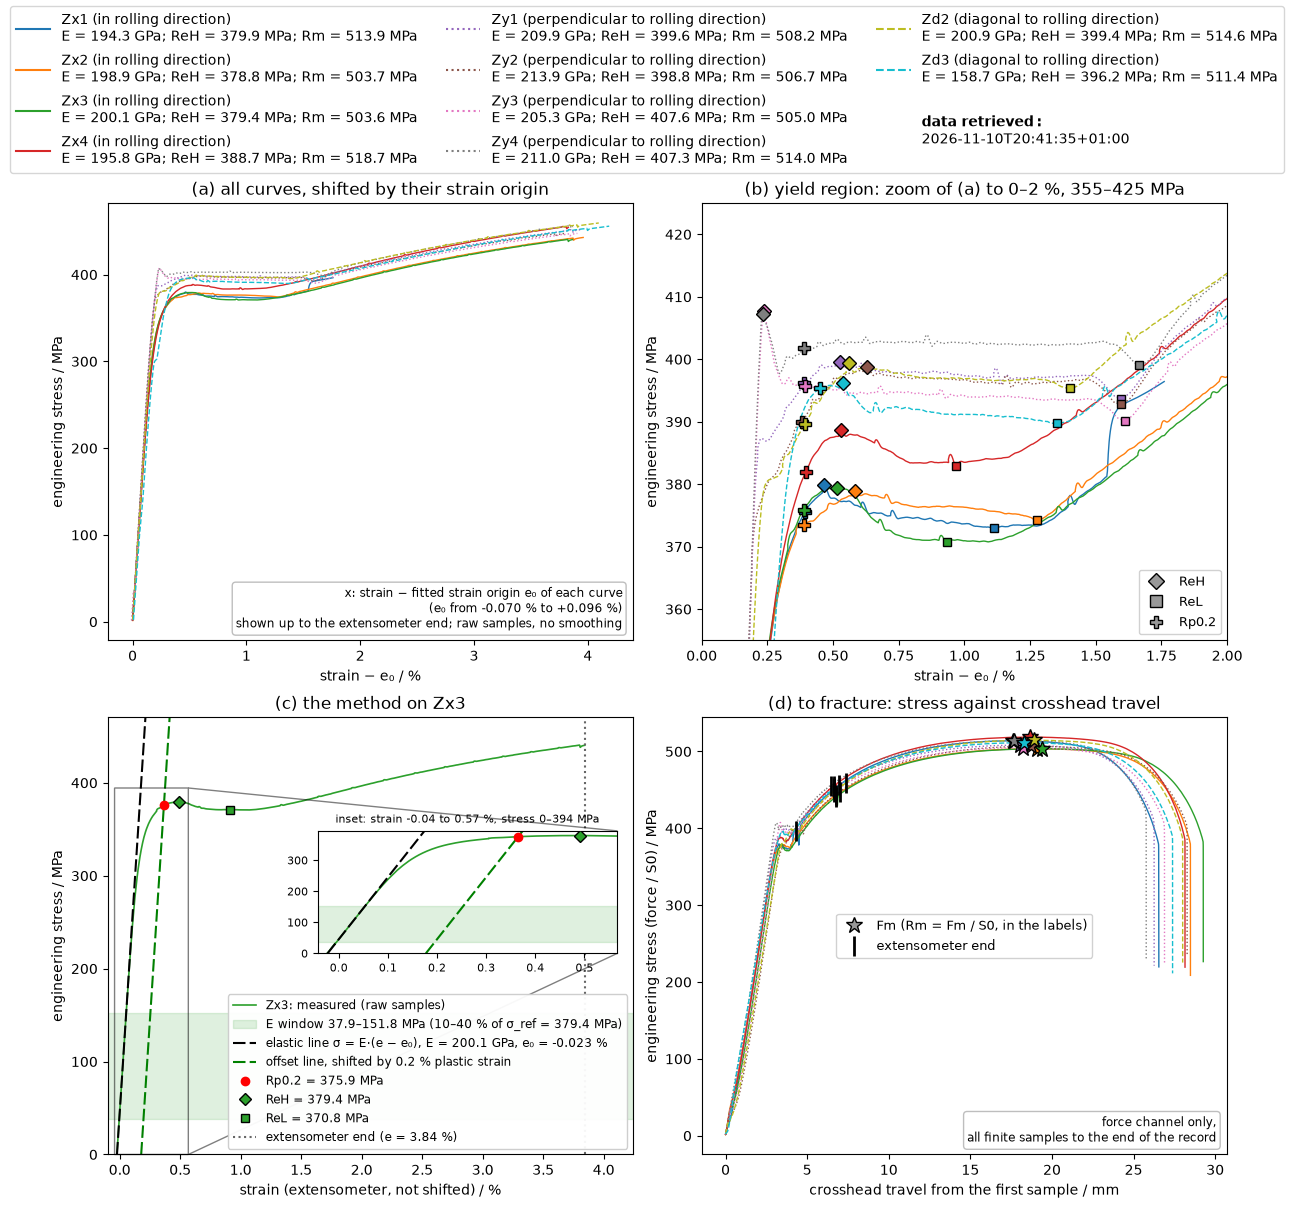

In [10]:
fig = plotting.curves_overview_figure(result, retrieved=retrieved)

**Results.** (e) Computed minus lab value per specimen and quantity, in units of the tolerance, so the green band is `within`. (f) ReH against Rm. (g) E against Rp0.2, with the E range over the fit-window grid as bars. (h) Mean ± sd per orientation, with each specimen and its S0-based uncertainty (k = 1), not combined.

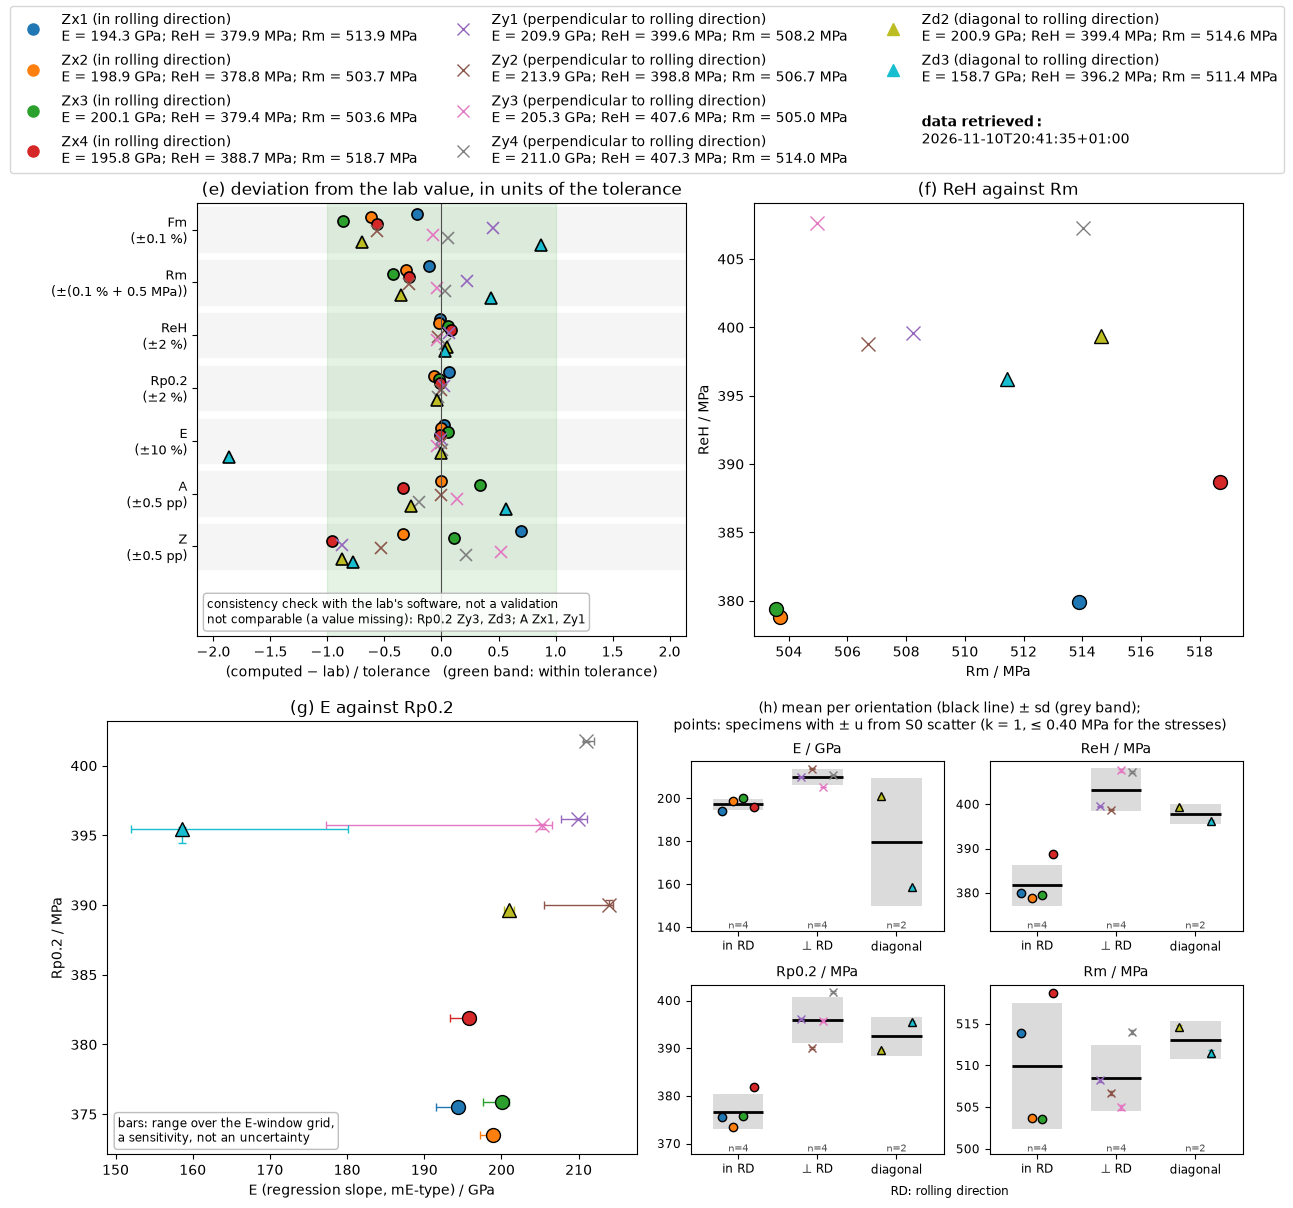

In [11]:
fig = plotting.results_overview_figure(result, retrieved=retrieved)

## 8. Limitations

The limitations of the method and of these data are listed once, in [notebook 02, section 11](02-tensile-method.ipynb); the cases of Zy3 and Zd3 are worked through there, step by step.

## Summary

- The same workflow analysed all ten specimens from the PMDco 2 and the PMDco 3 graphs; with identical curve bytes, every value, flag and comparison is identical (section 3).
- All ten specimens yield discontinuously; E, ReH, ReL, Rp0.2, Fm and Rm are defined on all of them, Ag and Agt on none, because the valid strain ends before the force maximum (section 4).
- ReH, Rp0.2, Rm and E agree with the lab's values to about one step of the lab's rounding or less, except Zd3's E (`outside`), whose elastic part is not straight (section 6).

Where to continue: [02](02-tensile-method.ipynb) for the method and its limitations, [01](01-tensile-data-from-graphs.ipynb) for the graphs and the profiles, [03](03-tensile-workflow-building.ipynb) for the workflow construction, [04](04-tensile-workflow-knowledge-graph.ipynb) for the run as a knowledge graph, [06](06-tensile-results-publication.ipynb) for the publication of the results.